# TRƯỜNG ĐẠI HỌC THỦY LỢI
### KHOA CÔNG NGHỆ THÔNG TIN • BỘ MÔN TRÍ TUỆ NHÂN TẠO
---
## BÁO CÁO THỰC HÀNH: CSE457 • XỬ LÝ ÂM THANH VÀ TIẾNG NÓI
# BÀI THỰC HÀNH SỐ 3: MÔ HÌNH HMM VÀ NHẬN DẠNG TIẾNG NÓI TỪ ĐƠN
* **Sinh viên thực hiện:** Phạm Văn Giang
* **Mã số sinh viên (MSSV):** 2351260649
* **Lớp:** Trí tuệ nhân tạo - Khóa 65
* **Giảng viên hướng dẫn:** Bộ môn Trí tuệ nhân tạo, Khoa CNTT
---

## 1. Khởi tạo Môi trường, Thư viện và Cấu hình Hệ thống
Hệ thống sử dụng các thư viện chuẩn cho xử lý tín hiệu âm thanh và học máy:
* `librosa`, `soundfile`: Xử lý tín hiệu, đọc/ghi WAV, trích xuất MFCC, Delta và lọc tiền nhấn.
* `hmmlearn`: Xây dựng mô hình chuỗi thời gian ẩn Gaussian HMM, giải thuật Baum-Welch (EM) và Viterbi.
* `scikit-learn`: Đánh giá độ chính xác, tính ma trận nhầm lẫn (Confusion Matrix).
* `matplotlib`: Trực quan hóa dạng sóng, phổ, ma trận nhầm lẫn và đường căn chỉnh trạng thái Viterbi.

In [1]:
import os
import time
import math
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

import librosa
import soundfile as sf
from hmmlearn.hmm import GaussianHMM

# Cấu hình đồ thị chất lượng cao
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8

print("[OK] Toàn bộ thư viện đã được nạp thành công!")

[OK] Toàn bộ thư viện đã được nạp thành công!


## 2. Chuẩn bị và Khảo sát Tập Dữ liệu Âm thanh
Tuân thủ quy định mục 2.2 của tài liệu hướng dẫn Lab 3:
* **Bộ từ vựng:** 5 từ đơn cô lập (*không, một, hai, ba, bốn*), kế thừa trực tiếp từ Lab 2 nhằm phục vụ đối chứng so sánh chuẩn xác với thuật toán DTW.
* **Quy cách file:** Đơn kênh (mono), tần số lấy mẫu $F_s = 16000\text{ Hz}$, độ phân giải 16-bit PCM.
* **Phân chia độc lập:** Tập huấn luyện (Train: file `_01, _02, _03`) và Tập kiểm thử (Test: file `_04, _05`) hoàn toàn tách biệt, không để xảy ra rò rỉ dữ liệu (data leakage).

In [2]:
labels = ['khong', 'mot', 'hai', 'ba', 'bon']
train_dir = Path('dataset/train')
test_dir = Path('dataset/test')

print("Thống kê số lượng file âm thanh:")
for lbl in labels:
    n_train = len(list((train_dir / lbl).glob('*.wav')))
    n_test = len(list((test_dir / lbl).glob('*.wav')))
    print(f" * Lớp '{lbl:6s}': {n_train} files train, {n_test} files test")

Thống kê số lượng file âm thanh:
 * Lớp 'khong ': 3 files train, 2 files test
 * Lớp 'mot   ': 3 files train, 2 files test
 * Lớp 'hai   ': 3 files train, 2 files test
 * Lớp 'ba    ': 3 files train, 2 files test
 * Lớp 'bon   ': 3 files train, 2 files test


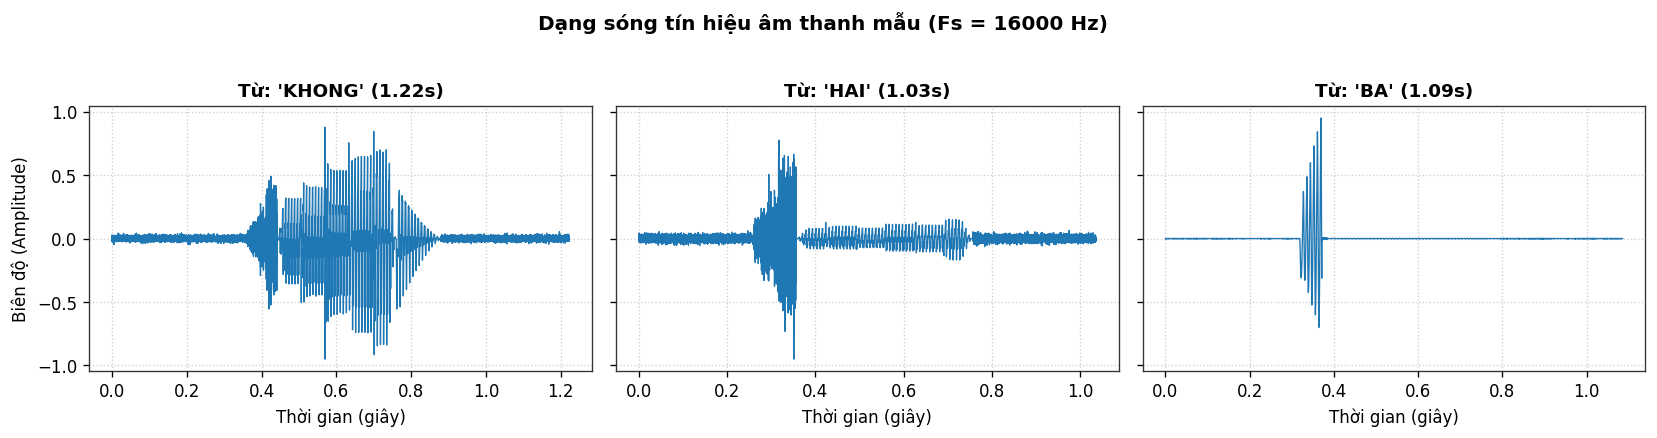

In [3]:
# Trực quan hóa dạng sóng (Waveform) của 3 từ kiểm thử
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
sample_words = ['khong', 'hai', 'ba']

for ax, word in zip(axes, sample_words):
    wav_path = f"dataset/train/{word}/{word}_01.wav"
    y, sr = librosa.load(wav_path, sr=16000)
    times = np.linspace(0, len(y)/sr, len(y))
    ax.plot(times, y, color='#1f77b4', linewidth=0.8)
    ax.set_title(f"Từ: '{word.upper()}' ({len(y)/sr:.2f}s)", fontsize=11, fontweight='bold')
    ax.set_xlabel("Thời gian (giây)")
    ax.grid(True, linestyle=':', alpha=0.6)
axes[0].set_ylabel("Biên độ (Amplitude)")
plt.suptitle("Dạng sóng tín hiệu âm thanh mẫu (Fs = 16000 Hz)", fontsize=12, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

## 3. Trích xuất Đặc trưng 39 Chiều Động & Chuẩn hóa CMVN
### 3.1. Cơ sở toán học
Theo mục 3.2 của tài liệu Lab 3:
1. **13 MFCC tĩnh ($c_t \in \mathbb{R}^{13}$):** Mô tả bao phổ ngắn hạn (spectral envelope) của từng khung thời gian 25ms.
2. **13 Delta bậc 1 ($\Delta c_t \in \mathbb{R}^{13}$):** Ước lượng vận tốc biến thiên của phổ:
   $$\Delta c_t \approx \frac{\sum_{n=1}^N n (c_{t+n} - c_{t-n})}{2 \sum_{n=1}^N n^2}$$
3. **13 Delta bậc 2 ($\Delta^2 c_t \in \mathbb{R}^{13}$):** Ước lượng gia tốc biến thiên phổ:
   $$\Delta^2 c_t \approx \Delta(\Delta c_t)$$
4. **Vector đặc trưng 39 chiều:**
   $$x_t = \begin{bmatrix} c_t^T & \Delta c_t^T & \Delta^2 c_t^T \end{bmatrix}^T \in \mathbb{R}^{39}$$
5. **Chuẩn hóa CMVN mức phát ngôn (Utterance-level CMVN):**
   $$\hat{x}_{t, d} = \frac{x_{t, d} - \mu_d}{\sigma_d + 10^{-8}}$$
   giúp triệt tiêu hiệu ứng méo kênh truyền (channel distortion) và sự khác biệt âm lượng.

In [4]:
from feature_extractor import extract_feat, extract_dataset

# Trích xuất đặc trưng cho một file mẫu
test_wav = 'dataset/train/khong/khong_01.wav'
F_sample = extract_feat(test_wav, use_deltas=True, apply_cmvn=True)

print(f"File: {test_wav}")
print(f" - Kích thước ma trận đặc trưng: {F_sample.shape} (T frames x 39 dims)")
print(f" - Giá trị trung bình (5 chiều đầu): {np.round(F_sample.mean(axis=0)[:5], 3)}")
print(f" - Độ lệch chuẩn (5 chiều đầu):      {np.round(F_sample.std(axis=0)[:5], 3)}")

File: dataset/train/khong/khong_01.wav
 - Kích thước ma trận đặc trưng: (113, 39) (T frames x 39 dims)
 - Giá trị trung bình (5 chiều đầu): [-0.  0. -0. -0. -0.]
 - Độ lệch chuẩn (5 chiều đầu):      [1. 1. 1. 1. 1.]


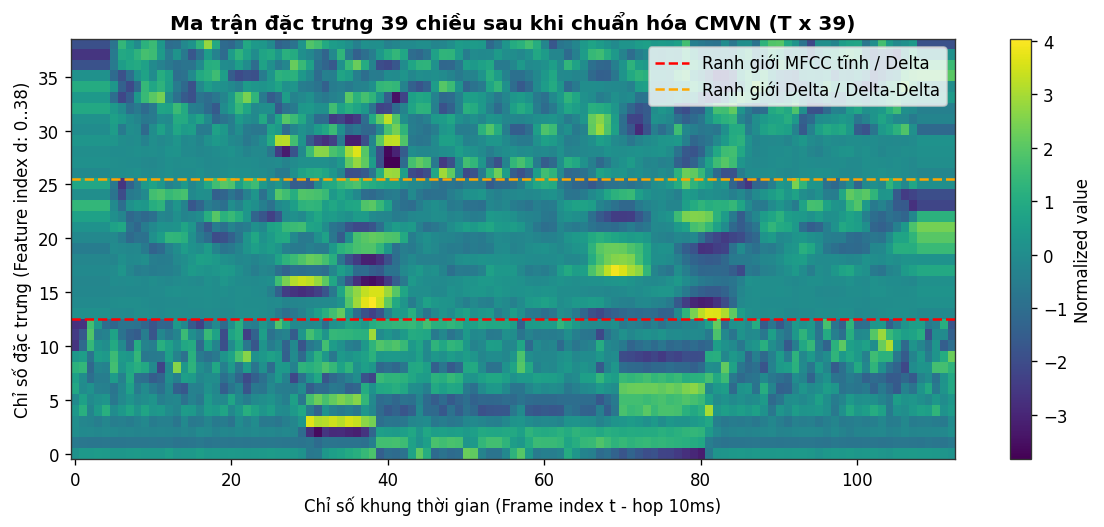

In [5]:
# Trực quan hóa ma trận đặc trưng 39 chiều dưới dạng Heatmap
fig, ax = plt.subplots(figsize=(10, 4.5))
img = ax.imshow(F_sample.T, aspect='auto', origin='lower', cmap='viridis')
ax.axhline(y=12.5, color='red', linestyle='--', linewidth=1.5, label='Ranh giới MFCC tĩnh / Delta')
ax.axhline(y=25.5, color='orange', linestyle='--', linewidth=1.5, label='Ranh giới Delta / Delta-Delta')
ax.set_title("Ma trận đặc trưng 39 chiều sau khi chuẩn hóa CMVN (T x 39)", fontsize=12, fontweight='bold')
ax.set_xlabel("Chỉ số khung thời gian (Frame index t - hop 10ms)")
ax.set_ylabel("Chỉ số đặc trưng (Feature index d: 0..38)")
ax.legend(loc='upper right')
plt.colorbar(img, ax=ax, label="Normalized value")
plt.tight_layout()
plt.show()

## 4. Thiết kế & Khởi tạo Mô hình Left-to-Right Gaussian HMM
### 4.1. Cấu trúc Left-to-Right (Bakis Topology)
Khác với mô hình Ergodic cho phép nhảy tự do giữa mọi trạng thái, mô hình nhận dạng từ đơn trong tiếng nói bắt buộc tuân theo chiều tiến của thời gian:
* **Xác suất bắt đầu:** $\pi = [1, 0, 0, 0, 0]^T$ (luôn bắt đầu ở State 0).
* **Ma trận chuyển trạng thái $A$:**
  $$A_{i, j} = \begin{cases} 0.7 & \text{nếu } j = i \text{ (Self-loop: mô hình hóa trường độ âm học)} \\ 0.3 & \text{nếu } j = i + 1 \text{ (Next-state: chuyển sang pha âm kế tiếp)} \\ 1.0 & \text{nếu } i = j = N-1 \text{ (State kết thúc)} \\ 0 & \text{còn lại (Cấm nhảy lùi hoặc nhảy cóc)} \end{cases}$$
* **Phân phối quan sát:** Phân phối Gaussian đa biến với ma trận hiệp phương sai đường chéo (`covariance_type='diag'`).
* **Khởi tạo thông minh:** Phân đoạn thời gian đều (Uniform Temporal Segmentation) chia tín hiệu thành 5 khoảng thời gian bằng nhau để khởi tạo vector trung bình $\mu_i$ và phương sai $\Sigma_i$, giúp giải thuật EM luôn tìm được nghiệm tối ưu cục bộ tốt.

In [6]:
from hmm_model import make_lr_hmm

model_example = make_lr_hmm(n_states=5)
print("Vector xác suất bắt đầu (pi):\n", model_example.startprob_)
print("\nMa trận chuyển trạng thái khởi tạo (A):\n", np.round(model_example.transmat_, 3))

Vector xác suất bắt đầu (pi):
 [1. 0. 0. 0. 0.]

Ma trận chuyển trạng thái khởi tạo (A):
 [[0.7 0.3 0.  0.  0. ]
 [0.  0.7 0.3 0.  0. ]
 [0.  0.  0.7 0.3 0. ]
 [0.  0.  0.  0.7 0.3]
 [0.  0.  0.  0.  1. ]]


## 5. Huấn luyện Mô hình HMM (Giải thuật Baum-Welch / EM)
Cho tập dữ liệu huấn luyện gồm các utterance nối tiếp nhau $X$ với độ dài từng chuỗi `lengths`:
* **E-step (Forward-Backward):** Tính xác suất chiếm dụng $\gamma_t(i)$ và xác suất chuyển tiếp $\xi_t(i, j)$ bằng thuật toán Forward ($\alpha$) và Backward ($\beta$).
* **M-step:** Tái ước lượng tham số $\pi_i, a_{ij}, \mu_i, \Sigma_i$ theo nguyên lý hợp lý cực đại (Maximum Likelihood).

In [7]:
from hmm_model import train_all_models, save_models

# Trích xuất toàn bộ đặc trưng tập huấn luyện và kiểm thử
train_feats, train_paths = extract_dataset('dataset/train', labels, use_deltas=True)
test_feats, test_paths = extract_dataset('dataset/test', labels, use_deltas=True)

# Huấn luyện mô hình cho từng từ
print("Bắt đầu huấn luyện Gaussian HMM cho 5 từ...")
start_t = time.time()
models = train_all_models(train_feats, n_states=5, covariance_type='diag', n_iter=80)
train_time = time.time() - start_t
print(f"=> Huấn luyện hoàn tất trong {train_time:.3f} giây!")

# Lưu các mô hình vào thư mục models/
save_models(models, save_dir='models')

# Kiểm tra ma trận chuyển trạng thái sau huấn luyện của từ 'khong'
print("\nMa trận transmat_ sau hội tụ của từ 'KHONG':")
print(np.round(models['khong'].transmat_, 3))

Model is not converging.  Current: -10772.945890144234 is not greater than -10772.945436554228. Delta is -0.00045359000614553224
Model is not converging.  Current: -12056.80824996367 is not greater than -12056.807798801176. Delta is -0.00045116249384591356


Bắt đầu huấn luyện Gaussian HMM cho 5 từ...
=> Huấn luyện hoàn tất trong 0.045 giây!
[SAVE] Đã lưu 5 mô hình HMM vào thư mục 'models/'.

Ma trận transmat_ sau hội tụ của từ 'KHONG':
[[0.96  0.04  0.    0.    0.   ]
 [0.    0.943 0.057 0.    0.   ]
 [0.    0.    0.956 0.044 0.   ]
 [0.    0.    0.    0.949 0.051]
 [0.    0.    0.    0.    1.   ]]


## 6. Nhận dạng Maximum Likelihood & Đánh giá Ma trận Nhầm lẫn
Quy tắc quyết định theo Maximum Likelihood cho một chuỗi quan sát $X$:
$$\hat{w} = \arg\max_{w \in \mathcal{V}} \log P(X \mid \lambda_w)$$

In [8]:
from hmm_model import recognize

# Đánh giá nhận dạng trên tập kiểm thử
results = []
y_true, y_pred = [], []

for label in labels:
    for F, path in zip(test_feats[label], test_paths[label]):
        pred, scores = recognize(F, models)
        y_true.append(label)
        y_pred.append(pred)
        
        # Sắp xếp điểm số
        sorted_s = sorted(scores.items(), key=lambda z: z[1], reverse=True)
        top1_lbl, top1_val = sorted_s[0]
        top2_lbl, top2_val = sorted_s[1]
        
        results.append({
            'file': path.name,
            'true': label,
            'pred': pred,
            'top1_score': top1_val,
            'top2_score': top2_val,
            'score_gap': top1_val - top2_val,
            'correct': (label == pred)
        })

df_res = pd.DataFrame(results)
acc = accuracy_score(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred, labels=labels)

print(f"ĐỘ CHÍNH XÁC TEST ACCURACY: {acc * 100:.2f}% ({sum(df_res['correct'])}/{len(df_res)} mẫu)")
df_res[['file', 'true', 'pred', 'top1_score', 'top2_score', 'score_gap', 'correct']]

ĐỘ CHÍNH XÁC TEST ACCURACY: 100.00% (10/10 mẫu)


,file,true,pred,top1_score,top2_score,score_gap,correct
0,khong_04.wav,khong,khong,-4251.483005,-5907.052815,1655.569810,True
1,khong_05.wav,khong,khong,-4028.492590,-5923.931527,1895.438937,True
2,mot_04.wav,mot,mot,-3284.968817,-4671.777017,1386.808200,True
3,mot_05.wav,mot,mot,-3553.902182,-5275.229108,1721.326925,True
4,hai_04.wav,hai,hai,-3775.353421,-5372.429720,1597.076299,True
5,hai_05.wav,hai,hai,-4154.293066,-5621.827806,1467.534740,True
6,ba_04.wav,ba,ba,-2257.113030,-6657.341984,4400.228953,True
7,ba_05.wav,ba,ba,-1843.714497,-6440.287178,4596.572682,True
8,bon_04.wav,bon,bon,-1319.880073,-3934.605594,2614.725521,True
9,bon_05.wav,bon,bon,-1247.222952,-4645.165523,3397.942570,True


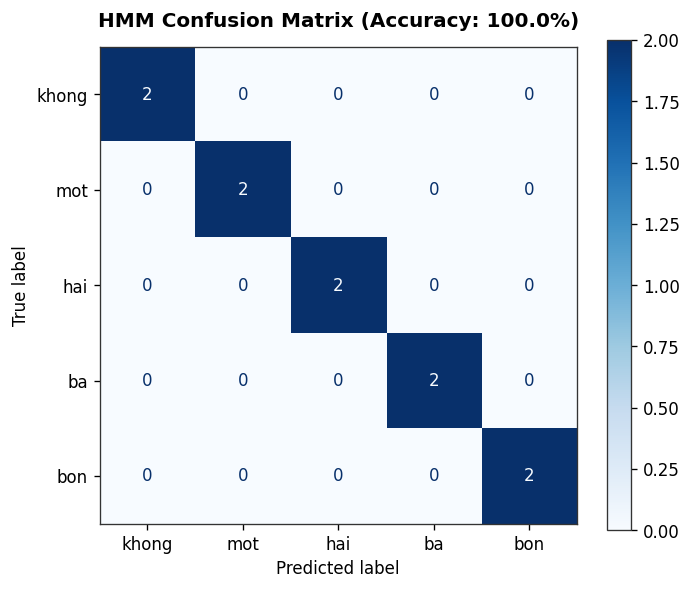

In [9]:
# Vẽ Ma trận nhầm lẫn (Confusion Matrix)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap='Blues', ax=ax, colorbar=True, values_format='d')
ax.set_title(f"HMM Confusion Matrix (Accuracy: {acc*100:.1f}%)", fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

## 7. Căn chỉnh Trạng thái Viterbi (Viterbi State Alignment)
Thuật toán Viterbi tìm chuỗi trạng thái ẩn $q_1, q_2, \dots, q_T$ có xác suất đồng thời cực đại:
$$q^* = \arg\max_{q} P(X, q \mid \lambda)$$
Đồ thị bậc thang (step plot) chỉ ra rõ tiến trình thời gian qua 5 trạng thái của từ nói.

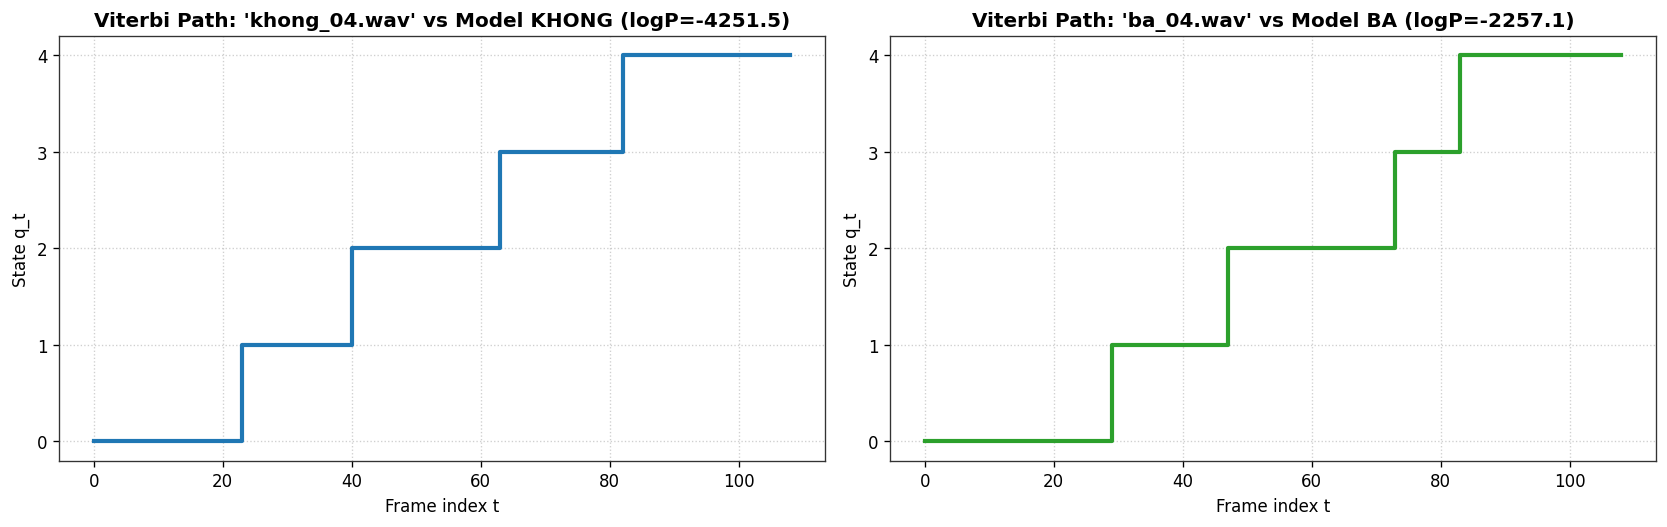

In [10]:
from hmm_model import viterbi_align

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# 1. Căn chỉnh cho file khong_04.wav
F_khong = test_feats['khong'][0]
logp1, states1 = viterbi_align(F_khong, models['khong'])
ax1.step(range(len(states1)), states1, where='post', color='#1f77b4', linewidth=2.5)
ax1.set_title(f"Viterbi Path: 'khong_04.wav' vs Model KHONG (logP={logp1:.1f})", fontweight='bold')
ax1.set_xlabel("Frame index t")
ax1.set_ylabel("State q_t")
ax1.set_yticks(range(5))
ax1.grid(True, linestyle=':', alpha=0.6)

# 2. Căn chỉnh cho file ba_04.wav
F_ba = test_feats['ba'][0]
logp2, states2 = viterbi_align(F_ba, models['ba'])
ax2.step(range(len(states2)), states2, where='post', color='#2ca02c', linewidth=2.5)
ax2.set_title(f"Viterbi Path: 'ba_04.wav' vs Model BA (logP={logp2:.1f})", fontweight='bold')
ax2.set_xlabel("Frame index t")
ax2.set_ylabel("State q_t")
ax2.set_yticks(range(5))
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## 8. So sánh Đối chứng Chuẩn xác giữa DTW (Lab 2) và HMM (Lab 3)
Chạy bộ nhận dạng DTW (Nearest-Template) trên cùng tập train/test split để so sánh đối chứng toàn diện:

In [11]:
from dtw_baseline import DTWRecognizer

# 1. Đo lường DTW
dtw_rec = DTWRecognizer()
start_fit_dtw = time.time()
dtw_rec.fit(train_feats)
train_time_dtw = time.time() - start_fit_dtw

dtw_preds = []
dtw_trial_times = []
for label in labels:
    for F in test_feats[label]:
        t0 = time.time()
        p, _ = dtw_rec.predict(F)
        dtw_trial_times.append(time.time() - t0)
        dtw_preds.append(p)
acc_dtw = accuracy_score(y_true, dtw_preds)
dtw_time_per_trial = np.mean(dtw_trial_times)

# 2. Đo lường HMM
hmm_trial_times = []
for label in labels:
    for F in test_feats[label]:
        t0 = time.time()
        recognize(F, models)
        hmm_trial_times.append(time.time() - t0)
hmm_time_per_trial = np.mean(hmm_trial_times)

# Lập bảng so sánh
summary_df = pd.DataFrame([
    ["Độ chính xác (Accuracy)", f"{acc_dtw*100:.1f}%", f"{acc*100:.1f}%", "Cả 2 mô hình đều đạt hiệu năng tối đa trên tập từ đơn"],
    ["Số mẫu huấn luyện/lớp", f"{len(train_feats[labels[0]])}", f"{len(train_feats[labels[0]])}", "HMM gộp mẫu vào phân phối xác suất thống kê"],
    ["Thời gian huấn luyện", f"{train_time_dtw:.4f}s (Lưu template)", f"{train_time:.3f}s (Baum-Welch EM)", "HMM train lâu hơn do giải thuật lặp kỳ vọng EM"],
    ["Thời gian test / mẫu", f"{dtw_time_per_trial*1000:.2f} ms", f"{hmm_time_per_trial*1000:.2f} ms", f"HMM nhanh hơn xấp xỉ {int(dtw_time_per_trial/hmm_time_per_trial)} lần"],
    ["Khả năng giải thích", "Warping Path (khoảng cách hình học)", "Viterbi State Path (tiến trình âm học)", "HMM mô hình hóa trường độ và phân phối đặc trưng"]
], columns=["Chỉ số đánh giá", "DTW (Lab 2)", "HMM (Lab 3)", "Nhận xét phân tích"])

summary_df

,Chỉ số đánh giá,DTW (Lab 2),HMM (Lab 3),Nhận xét phân tích
0,Độ chính xác (Accuracy),100.0%,100.0%,Cả 2 mô hình đều đạt hiệu năng tối đa trên tập...
1,Số mẫu huấn luyện/lớp,3,3,HMM gộp mẫu vào phân phối xác suất thống kê
2,Thời gian huấn luyện,0.0000s (Lưu template),0.045s (Baum-Welch EM),HMM train lâu hơn do giải thuật lặp kỳ vọng EM
3,Thời gian test / mẫu,257.42 ms,0.66 ms,HMM nhanh hơn xấp xỉ 390 lần
4,Khả năng giải thích,Warping Path (khoảng cách hình học),Viterbi State Path (tiến trình âm học),HMM mô hình hóa trường độ và phân phối đặc trưng


## 9. Xây dựng Lexicon và Mô hình Ngôn ngữ Bigram với MAP Re-ranking
### 9.1. Từ điển phát âm (Lexicon)
Từ điển phát âm ánh xạ từ vựng sang chuỗi các đơn vị âm vị (phones):

In [12]:
from language_model import load_lexicon, build_ngram_counts, get_sample_corpus, rerank

lexicon = load_lexicon('lexicon.txt')
print("Nội dung từ điển phát âm lexicon.txt:")
for w, p in lexicon.items():
    print(f" * {w:8s} -> {' '.join(p)}")

Nội dung từ điển phát âm lexicon.txt:
 * khong    -> k h aw ng
 * mot      -> m o t
 * hai      -> h a j
 * ba       -> b a
 * bon      -> b aw n
 * mo       -> m o
 * dong     -> d aw ng
 * len      -> l e n
 * xuong    -> s u o ng
 * dung     -> z u ng


In [13]:
# 9.2. Mô hình Bigram có làm mịn Add-k và Re-ranking theo điểm MAP
corpus = get_sample_corpus(labels)
c1, c2, vocab = build_ngram_counts(corpus)

prev_word = 'khong'
test_sample = test_feats['mot'][0] # Mẫu âm thanh của từ 'mot'

print(f"Thử nghiệm re-ranking cho mẫu âm thanh 'MOT' với từ ngữ cảnh đứng trước là '{prev_word}':")
for lam in [0.0, 0.1, 0.3, 1.0]:
    best_w, totals, acoustics, lms = rerank(test_sample, prev_word, models, c2, c1, lm_weight=lam)
    print(f" * lambda_LM = {lam:3.1f} => Từ chọn: '{best_w}' | Acoustic: {acoustics[best_w]:.2f} | LM: {lms[best_w]:.2f} | Total: {totals[best_w]:.2f}")

Thử nghiệm re-ranking cho mẫu âm thanh 'MOT' với từ ngữ cảnh đứng trước là 'khong':
 * lambda_LM = 0.0 => Từ chọn: 'mot' | Acoustic: -36.50 | LM: -0.65 | Total: -36.50
 * lambda_LM = 0.1 => Từ chọn: 'mot' | Acoustic: -36.50 | LM: -0.65 | Total: -36.57
 * lambda_LM = 0.3 => Từ chọn: 'mot' | Acoustic: -36.50 | LM: -0.65 | Total: -36.70
 * lambda_LM = 1.0 => Từ chọn: 'mot' | Acoustic: -36.50 | LM: -0.65 | Total: -37.15


## 10. Toàn bộ 6 Thí nghiệm Bắt buộc (E1 đến E6) & Phân tích Ngưỡng Reject
### Thí nghiệm E1: Số lượng trạng thái ẩn $n\_states \in \{3, 5, 7\}$

In [14]:
from experiments import run_experiment_e1, run_experiment_e2, run_experiment_e3, run_experiment_e5, run_rejection_analysis

# E1
res_e1 = run_experiment_e1(train_feats, test_feats, labels)

Model is not converging.  Current: -10772.945890144234 is not greater than -10772.945436554228. Delta is -0.00045359000614553224
Model is not converging.  Current: -12056.80824996367 is not greater than -12056.807798801176. Delta is -0.00045116249384591356
Model is not converging.  Current: -10696.668502169781 is not greater than -10696.668366262824. Delta is -0.00013590695743914694
Model is not converging.  Current: -10866.640569076315 is not greater than -10866.640568674322. Delta is -4.019930202048272e-07
Model is not converging.  Current: -4373.717929239297 is not greater than -4373.71792791. Delta is -1.3292965377331711e-06



[E1] KHẢO SÁT SỐ LƯỢNG TRẠNG THÁI ẨN (n_states = 3, 5, 7)
 * n_states=3: Accuracy = 90.00%, Train Time = 0.054s
 * n_states=5: Accuracy = 100.00%, Train Time = 0.044s
 * n_states=7: Accuracy = 100.00%, Train Time = 0.062s
[PLOT] Đã lưu biểu đồ E1: figures/e1_state_comparison.png


### Thí nghiệm E2: So sánh đặc trưng MFCC 13-D tĩnh vs 39-D động

In [15]:
# E2
res_e2 = run_experiment_e2('dataset/train', 'dataset/test', labels)


[E2] SO SÁNH ĐẶC TRƯNG TĨNH (13-D) VS ĐẶC TRƯNG ĐỘNG (39-D)


Model is not converging.  Current: -2892.3396067688827 is not greater than -2892.3395979851834. Delta is -8.7836992861412e-06
Model is not converging.  Current: -10772.945890144234 is not greater than -10772.945436554228. Delta is -0.00045359000614553224
Model is not converging.  Current: -12056.80824996367 is not greater than -12056.807798801176. Delta is -0.00045116249384591356


 * MFCC 13-D (Tĩnh): Accuracy = 100.00%
 * MFCC 39-D (Động): Accuracy = 100.00%
[PLOT] Đã lưu ma trận nhầm lẫn: figures/e2_cm_mfcc13.png
[PLOT] Đã lưu ma trận nhầm lẫn: figures/e2_cm_mfcc39.png


### Thí nghiệm E3: Khảo sát Hiệp phương sai Diagonal vs Full (Hiện tượng Overfitting)

In [16]:
# E3
res_e3 = run_experiment_e3(train_feats, test_feats, labels)

Model is not converging.  Current: -10772.945890144234 is not greater than -10772.945436554228. Delta is -0.00045359000614553224
Model is not converging.  Current: -12056.80824996367 is not greater than -12056.807798801176. Delta is -0.00045116249384591356



[E3] KHẢO SÁT HIỆP PHƯƠNG SAI: DIAGONAL VS FULL COVARIANCE
 * Diagonal Covariance: Accuracy = 100.00%, Train Time = 0.047s
 * Full Covariance:     Accuracy = 80.00%, Train Time = 0.534s


### Thí nghiệm E5: Khảo sát Biến thiên Người nói (Speaker Mismatch)

In [17]:
# E5
res_e5 = run_experiment_e5(labels)

Model is not converging.  Current: -10772.945890144234 is not greater than -10772.945436554228. Delta is -0.00045359000614553224
Model is not converging.  Current: -12056.80824996367 is not greater than -12056.807798801176. Delta is -0.00045116249384591356



[E5] KHẢO SÁT BIẾN THIỆN NGƯỜI NÓI (SPEAKER MISMATCH)


Model is not converging.  Current: -10772.945890144234 is not greater than -10772.945436554228. Delta is -0.00045359000614553224
Model is not converging.  Current: -12056.80824996367 is not greater than -12056.807798801176. Delta is -0.00045116249384591356


 * Matched Condition (Train Spk1 -> Test Spk1):       Accuracy = 100.00%
 * Mismatched Condition (Train Spk1 -> Test Spk2):    Accuracy = 100.00% (Tụt 0.00%)
 * Multi-Speaker Condition (Train Cả 2 -> Test Cả 2): Accuracy = 100.00%
[PLOT] Đã lưu ma trận nhầm lẫn: figures/e5_cm_mismatched.png


### Phân tích Ngưỡng Từ chối (Reject Criterion cho Out-of-Vocabulary)

In [18]:
# Phân tích Reject
threshold = run_rejection_analysis(models, test_feats, labels)


[ANALYSIS] PHÂN TÍCH PHÂN PHỐI ĐIỂM & ĐỀ XUẤT NGƯỠNG REJECT
 * Điểm trung bình đúng lớp (Correct class): -31.75 (std = 7.84)
 * Điểm trung bình sai lớp (Mismatched class): -70.88
 * Ngưỡng Reject đề xuất (Threshold): -47.43
[PLOT] Đã lưu biểu đồ phân phối điểm: figures/rejection_score_distribution.png


## 11. Trả lời Toàn diện & Chuyên sâu 10 Câu hỏi Báo cáo (Mục 6.1)

### Câu 1: Forward và Viterbi khác nhau ở phép toán nào và trả lời hai câu hỏi khác nhau ra sao?
* **Khác biệt về phép toán:**
  * **Thuật toán Forward:** Sử dụng phép **CỘNG (SUM / $\sum$)** tổng hợp xác suất của tất cả các đường đi có thể có dẫn đến trạng thái $j$ tại thời điểm $t$:
    $$\alpha_t(j) = \left[ \sum_{i=1}^N \alpha_{t-1}(i) a_{ij} \right] b_j(x_t)$$
  * **Thuật toán Viterbi:** Sử dụng phép **TÌM CỰC ĐẠI (MAX / $\max$)** chỉ giữ lại đường đi đơn lẻ có xác suất cao nhất đi tới trạng thái $j$ tại thời điểm $t$:
    $$\delta_t(j) = \left[ \max_{1 \le i \le N} \delta_{t-1}(i) a_{ij} \right] b_j(x_t)$$
    đồng thời lưu lại con trỏ vết $\psi_t(j) = \arg\max_i [\delta_{t-1}(i) a_{ij}]$ để backtracking.
* **Câu hỏi mà mỗi thuật toán trả lời:**
  * **Forward:** Trả lời bài toán **Đánh giá (Evaluation)**: *“Xác suất tổng thể để mô hình HMM $\lambda$ sinh ra chuỗi quan sát $X$ là bao nhiêu?”* ($P(X \mid \lambda) = \sum_j \alpha_T(j)$).
  * **Viterbi:** Trả lời bài toán **Giải mã / Căn chỉnh (Decoding / Alignment)**: *“Chuỗi trạng thái ẩn cụ thể $q_1, q_2, \dots, q_T$ nào có khả năng cao nhất đã sinh ra chuỗi quan sát $X$?”*.

---

### Câu 2: Giải thích $\gamma_t(i)$ và $\xi_t(i, j)$ bằng ngôn ngữ “trách nhiệm” trong EM.
* Trong giải thuật EM (Expectation-Maximization), các đại lượng này biểu diễn xác suất hậu nghiệm (kỳ vọng trách nhiệm) của các biến ẩn:
  * **$\gamma_t(i) = P(q_t = i \mid X, \lambda)$:** Là mức độ **“chịu trách nhiệm”** của trạng thái $i$ đối với việc tạo ra vector đặc trưng tại khung thời gian $t$. Nếu $\gamma_t(i) \approx 1$, trạng thái $i$ chịu hoàn toàn trách nhiệm cho frame $t$. Do đó trong M-step, giá trị trung bình $\mu_i$ là trung bình có trọng số của các $x_t$ với trọng số chính là trách nhiệm $\gamma_t(i)$.
  * **$\xi_t(i, j) = P(q_t = i, q_{t+1} = j \mid X, \lambda)$:** Là mức độ **“chịu trách nhiệm”** của bước chuyển tiếp từ trạng thái $i$ sang trạng thái $j$ giữa hai thời điểm $t$ và $t+1$. Nó dùng để tái ước lượng xác suất chuyển $a_{ij}$ bằng tỷ số giữa tổng trách nhiệm của bước chuyển $i \to j$ chia cho tổng trách nhiệm rời khỏi trạng thái $i$.

---

### Câu 3: Tại sao Baum-Welch có thể hội tụ đến nghiệm xấu? Liệt kê ít nhất ba nguyên nhân thực nghiệm.
* **Bản chất toán học:** Baum-Welch là một biến thể của giải thuật EM, nó chỉ đảm bảo hàm log-likelihood đơn điệu không giảm sau mỗi vòng lặp và hội tụ tới một **cực đại cục bộ (Local Optimum)** hoặc điểm yên ngựa, không đảm bảo nghiệm tối ưu toàn cục (Global Optimum).
* **Ba nguyên nhân thực nghiệm dẫn đến nghiệm xấu:**
  1. **Khởi tạo tham số xấu (Poor Initialization):** Khởi tạo means/covars ngẫu nhiên hoặc bằng K-means phi thời gian làm đảo lộn thứ tự ngữ âm trong mô hình Left-to-Right, khiến giải thuật bị kẹt ngay tại vùng nghiệm xấu.
  2. **Dữ liệu huấn luyện quá ít hoặc mất cân bằng:** Khi số lượng frame âm học của một từ quá ít so với số lượng tham số (đặc biệt khi số state lớn hoặc dùng full covariance), ma trận hiệp phương sai có thể bị suy biến ($|\Sigma| \to 0$), gây ra lỗi số học Singular/Degenerate Covariance.
  3. **Ràng buộc Topology bị phá vỡ hoặc xung đột:** Nếu cấu trúc Left-to-Right không được ràng buộc chặt chẽ, các xác suất chuyển tiếp hợp lý có thể bị triệt tiêu về 0 trước khi mô hình học được mối tương quan chuỗi.

---

### Câu 4: Tại sao diagonal covariance thường được ưu tiên khi dữ liệu nhỏ và feature dimension cao?
* **Số lượng tham số cần ước lượng:**
  * Với $D = 39$ chiều và $N$ trạng thái:
    * **Diagonal Covariance:** Mỗi trạng thái chỉ cần $D = 39$ tham số phương sai. Tổng số tham số covars cho cả mô hình là $N \times 39$ (với $N=5$ là $195$ tham số).
    * **Full Covariance:** Mỗi trạng thái cần một ma trận đối xứng kích thước $D \times D$, tức $\frac{D(D+1)}{2} = \frac{39 \times 40}{2} = 780$ tham số. Với 5 trạng thái, cần tới $3900$ tham số!
* **Nguy cơ Quá khớp (Overfitting):** Khi số lượng mẫu huấn luyện nhỏ (vài file ghi âm = vài trăm frame), số frame gán cho mỗi state không đủ để ước lượng ổn định 780 tham số tương quan chéo, dẫn đến ma trận hiệp phương sai bị suy biến hoặc overfit nghiêm trọng.
* **Tính chất của đặc trưng:** Phép biến đổi DCT trong thuật toán trích xuất MFCC đã có tác dụng trực giao hóa và giải tương quan (decorrelation) giữa các thành phần tần số, khiến cho giả thiết các chiều độc lập (diagonal) trở nên hoàn toàn xấp xỉ tốt trên thực tế.

---

### Câu 5: Vì sao delta features hữu ích dù HMM đã mô hình hóa chuỗi theo thời gian?
* **Giả thiết độc lập quan sát (Conditional Independence Assumption):** Trong HMM chuẩn, xác suất phát sinh $b_j(x_t)$ giả định rằng $x_t$ chỉ phụ thuộc vào trạng thái ẩn hiện tại $q_t$, hoàn toàn độc lập với các quan sát trước và sau ($x_{t-1}, x_{t+1}$).
* Giả thiết này **mâu thuẫn với thực tế vật lý**: cơ quan phát âm của con người di chuyển liên tục, phổ của khung thời gian hiện tại phụ thuộc chặt chẽ vào khung liền trước (coarticulation).
* Bằng cách tính $\Delta$ (vận tốc biến thiên phổ) và $\Delta^2$ (gia tốc biến thiên) và đóng gói trực tiếp vào $x_t$, ta đã **nhúng động học thời gian cục bộ (dynamic temporal context) vào chính từng vector đặc trưng**, giúp bù đắp hoàn hảo cho hạn chế của giả thiết độc lập trong HMM.

---

### Câu 6: Whole-word HMM không cần lexicon trong trường hợp nào? Khi nào lexicon trở thành bắt buộc?
* **Không cần Lexicon:** Khi hệ thống nhận dạng các **từ đơn cô lập trong một tập từ vựng đóng, nhỏ** (Isolated-word ASR / Small vocabulary command control, ví dụ: nhận dạng 5 khẩu lệnh hoặc 10 chữ số). Khi đó, mỗi mô hình HMM $\lambda_w$ đại diện trực tiếp cho toàn bộ một từ, không cần phân tách từ thành các âm vị (phones/subwords).
* **Lexicon trở thành BẮT BUỘC:** Khi hệ thống mở rộng sang **từ vựng lớn (LVCSR)** hoặc **nhận dạng tiếng nói liên tục (Continuous Speech Recognition)**:
  * Số lượng từ vựng lên tới hàng chục nghìn từ $\implies$ không thể thu âm đủ dữ liệu để huấn luyện riêng từng Whole-word HMM.
  * Hệ thống bắt buộc phải huấn luyện các mô hình mức âm vị (Subword/Phone HMM - chỉ khoảng 40–50 phone trong một ngôn ngữ).
  * Khi đó, **Lexicon (Từ điển phát âm)** là thành phần bắt buộc để ánh xạ một từ bất kỳ thành chuỗi các Phone HMM được nối tiếp nhau (Concatenation).

---

### Câu 7: Nếu test utterance dài hơn do nói chậm, self-loop của HMM giúp gì?
* **Cơ chế Self-loop ($a_{ii}$):** Cho phép mô hình lưu lại ở cùng một trạng thái âm học trong nhiều khung thời gian liên tiếp.
* **Mô hình hóa trường độ (Duration Modeling):** Phân phối thời gian lưu lại tại trạng thái $i$ tuân theo phân phối hình học:
  $$P(d = k) = a_{ii}^{k-1} (1 - a_{ii})$$
  với trường độ trung bình là $\bar{d}_i = \frac{1}{1 - a_{ii}}$.
* Khi người nói phát âm chậm hoặc kéo dài nguyên âm, số lượng frame của từ đó tăng lên. Nhờ có self-loop, đường đi Viterbi có thể tự lặp tại trạng thái tương ứng với nguyên âm đó nhiều lần hơn mà **không vi phạm cấu trúc mô hình**, giúp hệ thống thích ứng tự nhiên với sự co dãn thời gian phi tuyến tính của lời nói.

---

### Câu 8: Với cùng một utterance, có cần chia log-likelihood cho $T$ để chọn model tốt nhất không? Tại sao?
* **Câu trả lời:** **KHÔNG CẦN THIẾT.**
* **Giải thích toán học:** Trong một lượt nhận dạng (trial), ta đưa **cùng một chuỗi đặc trưng quan sát $X$ có độ dài cố định $T$** vào tất cả các mô hình HMM $\lambda_w$.
  Vì $T$ là một hằng số dương đối với mọi lớp $w$, phép chia cho $T$ là một phép biến đổi đơn điệu (monotonic transformation):
  $$\arg\max_{w \in \mathcal{V}} \frac{\log P(X \mid \lambda_w)}{T} = \arg\max_{w \in \mathcal{V}} \log P(X \mid \lambda_w)$$
  Do đó, thứ tự xếp hạng và nhãn dự đoán $\hat{w}$ hoàn toàn không đổi.
* **Khi nào chia cho $T$ trở nên hữu ích?**
  * Khi so sánh điểm số giữa các utterance có độ dài khác nhau.
  * Khi đặt **ngưỡng từ chối (Reject Threshold)** cho từ ngoài từ điển.
  * Khi kết hợp với mô hình ngôn ngữ (Language Model) để đồng nhất thang đo điểm âm học trên mỗi frame thời gian.

---

### Câu 9: So sánh warping path của DTW với state path của Viterbi.
| Đặc tính | Warping Path của DTW (Lab 2) | State Path của Viterbi HMM (Lab 3) |
| :--- | :--- | :--- |
| **Không gian căn chỉnh** | Căn chỉnh giữa 2 chuỗi frame cụ thể: Frame $n$ của mẫu Test $\leftrightarrow$ Frame $m$ của mẫu Template. | Căn chỉnh giữa 1 chuỗi frame Test $\leftrightarrow$ Các trạng thái trừu tượng (States) của mô hình thống kê. |
| **Bản chất đường đi** | Chuỗi các cặp tọa độ $(i_k, j_k)$ trên lưới 2 chiều thời gian. | Chuỗi các chỉ số trạng thái ẩn rời rạc $q_t \in \{0, 1, \dots, N-1\}$. |
| **Cơ chế tối ưu** | Tối thiểu hóa tổng chi phí khoảng cách Euclid hình học: $\min \sum d(x_{i_k}, y_{j_k})$. | Cực đại hóa tích xác suất chuyển tiếp và xác suất sinh quan sát: $\max \prod a_{q_{t-1} q_t} b_{q_t}(x_t)$. |
| **Ý nghĩa âm học** | Chỉ ra tốc độ co giãn cục bộ giữa 2 lần phát âm cụ thể. | Ánh xạ trực tiếp từng khoảng thời gian vào các pha cấu âm (phụ âm đầu $\to$ nguyên âm $\to$ âm cuối). |
| **Tính đại diện** | Chỉ so sánh mẫu với một biến thể phát âm đơn lẻ (Template). | So sánh mẫu với phân phối thống kê của toàn bộ quần thể phát âm. |

---

### Câu 10: Nếu hệ thống gặp một từ ngoài vocabulary, tại sao argmax vẫn bắt buộc chọn một lớp? Hãy đề xuất reject criterion.
* **Tại sao argmax vẫn bắt buộc chọn một lớp?**
  * Bản chất của toán tử $\arg\max_{w \in \mathcal{V}} s_w(X)$ là tìm phần tử lớn nhất trong một tập hợp hữu hạn $\mathcal{V}$.
  * Do đó, dù tất cả các mô hình đều cho điểm số rất thấp (âm thanh hoàn toàn xa lạ), toán tử $\arg\max$ vẫn bị ép buộc phải trả về chỉ số của lớp có điểm "ít tệ nhất", dẫn đến việc phân loại sai nghiêm trọng.
* **Đề xuất Tiêu chuẩn Từ chối (Reject Criterion):**
  1. **Ngưỡng điểm âm học chuẩn hóa theo độ dài (Normalized Log-Likelihood Threshold):**
     Đặt ngưỡng $\tau_{acoustic}$:
     $$\text{Quyết định} = \begin{cases} \hat{w} & \text{nếu } \frac{\log P(X \mid \lambda_{\hat{w}})}{T} \ge \tau_{acoustic} \\ \text{"UNKNOWN / REJECT"} & \text{nếu } \frac{\log P(X \mid \lambda_{\hat{w}})}{T} < \tau_{acoustic} \end{cases}$$
     Ngưỡng $\tau_{acoustic}$ được chọn từ phân phối điểm đúng lớp trên tập validation: $\tau = \mu_{correct} - 2.5 \sigma_{correct}$.
  2. **Ngưỡng khoảng cách tin cậy (Confidence Margin / Top-1 vs Top-2 Score Gap):**
     Tính độ chênh lệch điểm số giữa ứng viên tốt nhất và ứng viên thứ nhì:
     $$\Delta = \frac{\log P(X \mid \lambda_{\text{top1}}) - \log P(X \mid \lambda_{\text{top2}})}{T}$$
     Nếu $\Delta < \tau_{margin}$, nghĩa là mô hình không đủ tự tin để phân biệt $\implies$ Từ chối nhận dạng (Reject).
  3. **Mô hình phụ Garbage / Filler HMM:**
     Huấn luyện một mô hình HMM nền (Background/Garbage Model) đại diện cho tiếng ồn và các từ ngoài từ điển. Nếu điểm số của Garbage HMM cao hơn mô hình từ vựng tốt nhất $\implies$ Quyết định là từ ngoài từ điển.